# Two Honest Charts, Two Opposite Stories: What Climate Data Teaches Us About Python Axes

*A Python Plotly tutorial using NASA temperature data to show why the most consequential design decision in a chart is where the y-axis starts*

**Data:** nasa_giss_anomaly.csv, https://data.giss.nasa.gov/gistemp/tabledata_v4/GLB.Ts+dSST.csv, data to 2025

**Article:** (link added when the article is published)

Run the cells in order. Dataset files are in the same folder as this notebook.

In [1]:
import plotly.io as pio
pio.renderers.default = "notebook_connected+png"  # interactive in Jupyter, image on GitHub

### The Dataset

The NASA Goddard Institute for Space Studies publishes its Land-Ocean Temperature Index as a free CSV going back to 1880. It records the global mean surface temperature as an *anomaly* — the difference from a 1951–1980 baseline average — in degrees Celsius. It is one of the most widely cited climate datasets in the world.

In [2]:
import pandas as pd

df = pd.read_csv('nasa_giss_anomaly.csv', skiprows=2,
                 names=['Year', 'No_Smoothing', 'Lowess5'])
print(df.columns.tolist())
print(df.head())

['Year', 'No_Smoothing', 'Lowess5']
   Year  No_Smoothing  Lowess5
0  1880         -0.17    -0.10
1  1881         -0.09    -0.13
2  1882         -0.11    -0.17
3  1883         -0.18    -0.20
4  1884         -0.28    -0.24


### Chart 1: The Misleading Version

Let's start by making the warming as invisible as possible.

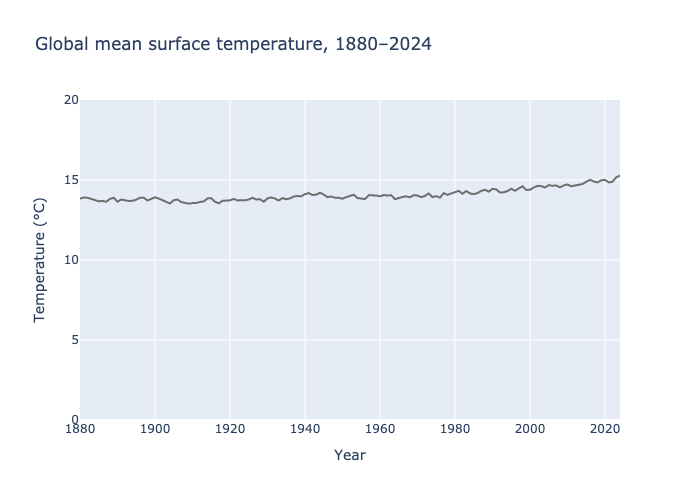

In [3]:
import pandas as pd
import plotly.graph_objects as go

df = pd.read_csv('nasa_giss_anomaly.csv', skiprows=2,
                 names=['Year', 'No_Smoothing', 'Lowess5'])
df = df[df['Year'] <= 2024].copy()
df['Absolute'] = df['No_Smoothing'] + 14.0

fig = go.Figure()
fig.add_trace(go.Scatter(
    x=df['Year'], y=df['Absolute'],
    mode='lines', line=dict(color='#6E6E6E', width=2)
))
fig.update_layout(
    title='Global mean surface temperature, 1880–2024',
    yaxis_title='Temperature (°C)', xaxis_title='Year'
)
fig.update_yaxes(range=[0, 20])
fig.show()

### Chart 2: The Alarming Version

Now let's make the same data as alarming as possible.

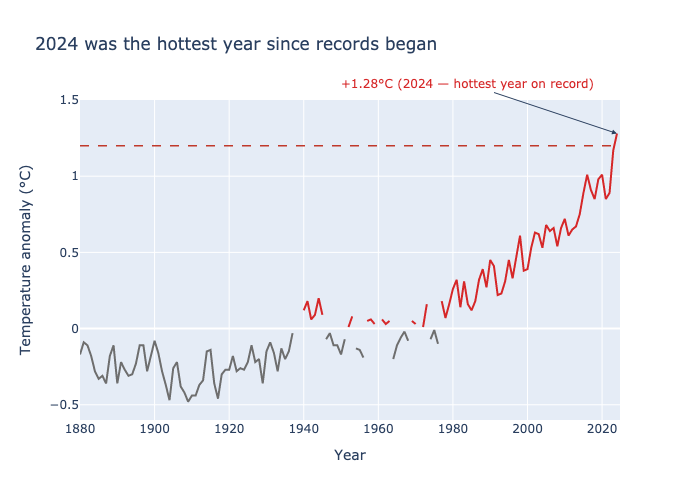

In [4]:
import pandas as pd
import plotly.graph_objects as go

df = pd.read_csv('nasa_giss_anomaly.csv', skiprows=2,
                 names=['Year', 'No_Smoothing', 'Lowess5'])
df = df[df['Year'] <= 2024].copy()

df_neg = df.copy()
df_neg.loc[df['No_Smoothing'] >= 0, 'No_Smoothing'] = None

df_pos = df.copy()
df_pos.loc[df['No_Smoothing'] < 0, 'No_Smoothing'] = None

fig = go.Figure()
fig.add_trace(go.Scatter(
    x=df_neg['Year'], y=df_neg['No_Smoothing'],
    mode='lines', line=dict(color='#6E6E6E', width=2), connectgaps=False
))
fig.add_trace(go.Scatter(
    x=df_pos['Year'], y=df_pos['No_Smoothing'],
    mode='lines', line=dict(color='#D62728', width=2), connectgaps=False
))
fig.add_hline(y=1.2, line=dict(color='#C0392B', dash='dash', width=1.5))
fig.add_annotation(
    x=2024, y=1.28,
    text='+1.28°C (2024 — hottest year on record)',
    showarrow=True, arrowhead=2, ax=-150, ay=-50,
    font=dict(color='#D62728')
)
fig.update_layout(
    title='2024 was the hottest year since records began',
    yaxis_title='Temperature anomaly (°C)', xaxis_title='Year',
    showlegend=False
)
fig.update_yaxes(range=[-0.6, 1.5])
fig.show()

### Chart 3: The Honest Version

Here is what a chart looks like when it tries to show both things.

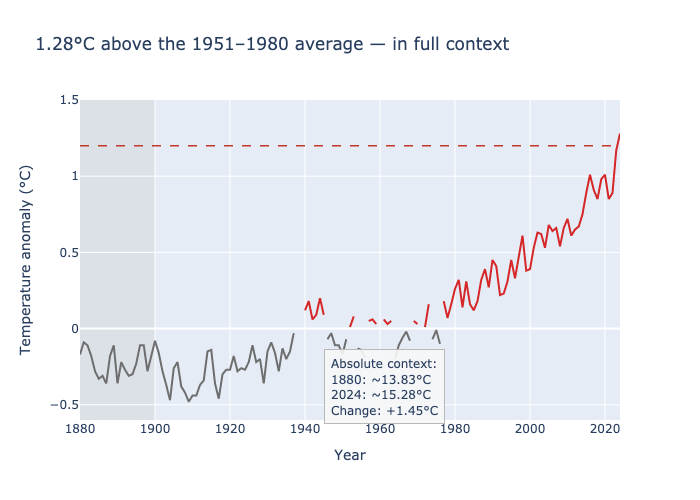

In [5]:
import pandas as pd
import plotly.graph_objects as go

df = pd.read_csv('nasa_giss_anomaly.csv', skiprows=2,
                 names=['Year', 'No_Smoothing', 'Lowess5'])
df = df[df['Year'] <= 2024].copy()

df_neg = df.copy()
df_neg.loc[df['No_Smoothing'] >= 0, 'No_Smoothing'] = None

df_pos = df.copy()
df_pos.loc[df['No_Smoothing'] < 0, 'No_Smoothing'] = None

fig = go.Figure()
fig.add_vrect(x0=1880, x1=1900,
              fillcolor='rgba(200,200,200,0.3)', layer='below', line_width=0)
fig.add_trace(go.Scatter(
    x=df_neg['Year'], y=df_neg['No_Smoothing'],
    mode='lines', line=dict(color='#6E6E6E', width=2), connectgaps=False
))
fig.add_trace(go.Scatter(
    x=df_pos['Year'], y=df_pos['No_Smoothing'],
    mode='lines', line=dict(color='#D62728', width=2), connectgaps=False
))
fig.add_hline(y=1.2, line=dict(color='#C0392B', dash='dash', width=1.5))
fig.add_annotation(
    x=1945, y=-0.38,
    text='Absolute context:<br>1880: ~13.83°C<br>2024: ~15.28°C<br>Change: +1.45°C',
    showarrow=False, xanchor='left', align='left',
    bgcolor='rgba(248,248,248,0.9)', bordercolor='#B8B8B8', borderpad=6
)
fig.update_layout(
    title='1.28°C above the 1951–1980 average — in full context',
    yaxis_title='Temperature anomaly (°C)', xaxis_title='Year',
    showlegend=False
)
fig.update_yaxes(range=[-0.6, 1.5])
fig.show()